In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

In [2]:
df=pd.read_csv(r"C:\Users\DELL\OneDrive\Desktop\Datasets\Fraud.csv")
df.head(5)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


***BASIC CHECKS***

In [3]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')

## Dataset Column Descriptions

| Column Name | Description |
|---|---|
| `step` | Maps a unit of time in the real world. In this dataset, 1 step represents 1 hour. The total number of steps is 744, representing a 30-day simulation. |
| `type` | Type of transaction. The possible values are `CASH-IN`, `CASH-OUT`, `DEBIT`, `PAYMENT`, and `TRANSFER`. |
| `amount` | Amount of the transaction in local currency. |
| `nameOrig` | Customer who initiated the transaction. |
| `oldbalanceOrg` | Initial balance of the origin account before the transaction. |
| `newbalanceOrig` | New balance of the origin account after the transaction. |
| `nameDest` | Customer or account receiving the transaction. |
| `oldbalanceDest` | Initial balance of the destination account before the transaction. Balance information is not available for customers whose account names start with `M` (merchants). |
| `newbalanceDest` | New balance of the destination account after the transaction. Balance information is not available for customers whose account names start with `M` (merchants). |
| `isFraud` | Indicates whether a transaction was performed by fraudulent agents in the simulation. The fraudulent agents attempt to take control of customer accounts, transfer funds to another account, and then cash out the money from the system. |
| `isFlaggedFraud` | Indicates whether a transaction was flagged as potentially illegal by the business model. In this dataset, an illegal attempt is defined as a transfer of more than 200,000 in a single transaction. |

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
#No duplicates

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 706.2 MB


In [7]:
df.drop(['nameOrig', 'nameDest'], axis=1, inplace=True)


### Dataset Description

The dataset contains **6,362,620 transaction records and 11 columns**, representing financial transactions and their associated details.

The dataset consists of 5 floating-point columns, 3 integer columns, and 3 string columns. 
The `step` column represents the transaction time step, while `type` indicates the type of transaction and `amount` records the transaction value.
The `nameOrig` and `nameDest` columns identify the originating and destination accounts, respectively.

The columns `oldbalanceOrg` and `newbalanceOrig` represent the origin account balances before and after the transaction,
while `oldbalanceDest` and `newbalanceDest` represent the destination account balances before and after the transaction.

The `isFraud` column is the target variable used to identify fraudulent transactions, where 1 indicates fraud and 0 indicates a legitimate transaction. The `isFlaggedFraud` column indicates whether a transaction was flagged by the existing fraud-detection system.





***STATISTICAL ANALYSIS***

In [8]:
pd.set_option('display.float_format', '{:.2f}'.format)

df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6362620.00,6362620.00,6362620.00,6362620.00,6362620.00,6362620.00,6362620.00,6362620.00
mean,243.40,179861.90,833883.10,855113.67,1100701.67,1224996.40,0.00,0.00
std,142.33,603858.23,2888242.67,2924048.50,3399180.11,3674128.94,0.04,0.00
min,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,156.00,13389.57,0.00,0.00,0.00,0.00,0.00,0.00
50%,239.00,74871.94,14208.00,0.00,132705.66,214661.44,0.00,0.00
75%,335.00,208721.48,107315.18,144258.41,943036.71,1111909.25,0.00,0.00
max,743.00,92445516.64,59585040.37,49585040.37,356015889.35,356179278.92,1.00,1.00


### Descriptive Statistics

The descriptive statistics summarize the distribution of the numerical variables in the dataset. All numerical columns contain **6,362,620 records**, indicating that there are no missing values in these columns based on the count values.

- **Step:** The transaction step ranges from 1 to 743, with a mean of 243.40 and a standard deviation of 142.33.
- **Transaction amount:** The amount column has a wide range of values, from 0 to approximately 356.18 million, indicating substantial variation in transaction values.
- **Account balances:** The origin and destination balance columns show considerable variation, with some accounts having zero balances and others having very large balances.
- **Fraud indicator (`isFraud`):** This is a binary target variable, with 0 representing legitimate transactions and 1 representing fraudulent transactions.
- **Flagged fraud (`isFlaggedFraud`):** This is also a binary variable. 

The differences between the means, medians, and maximum values of several numerical variables suggest that their distributions may be highly skewed. 

In [9]:
df.describe(include=object)

,type
count,6362620
unique,5
top,CASH_OUT
freq,2237500


### Descriptive Statistics of the Categorical Variable

The `type` column contains **6,362,620 transaction records** and has **5 unique transaction types**. The most frequently occurring transaction type is `CASH_OUT`, with **2,237,500 transactions**. This indicates that cash-out transactions represent a major category in the dataset.



In [10]:
df.nunique()

step                  743
type                    5
amount            5316900
oldbalanceOrg     1845844
newbalanceOrig    2682586
oldbalanceDest    3614697
newbalanceDest    3555499
isFraud                 2
isFlaggedFraud          2
dtype: int64

In [11]:
numcol = ['amount', 'oldbalanceOrg', 'newbalanceOrig',
          'oldbalanceDest', 'newbalanceDest']

discol = ['step']

catcol = ['type', 'isFraud', 'isFlaggedFraud']

In [12]:
for i in catcol:
    print(i)
    print(df[i].unique())
    print('***************************')

type
<ArrowStringArray>
['PAYMENT', 'TRANSFER', 'CASH_OUT', 'DEBIT', 'CASH_IN']
Length: 5, dtype: str
***************************
isFraud
[0 1]
***************************
isFlaggedFraud
[0 1]
***************************


***DATA PREPROCESSING***

**NULL VALUES**

In [13]:
df.isnull().sum()

step              0
type              0
amount            0
oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [14]:
#No null values

**OUTLIERS**

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

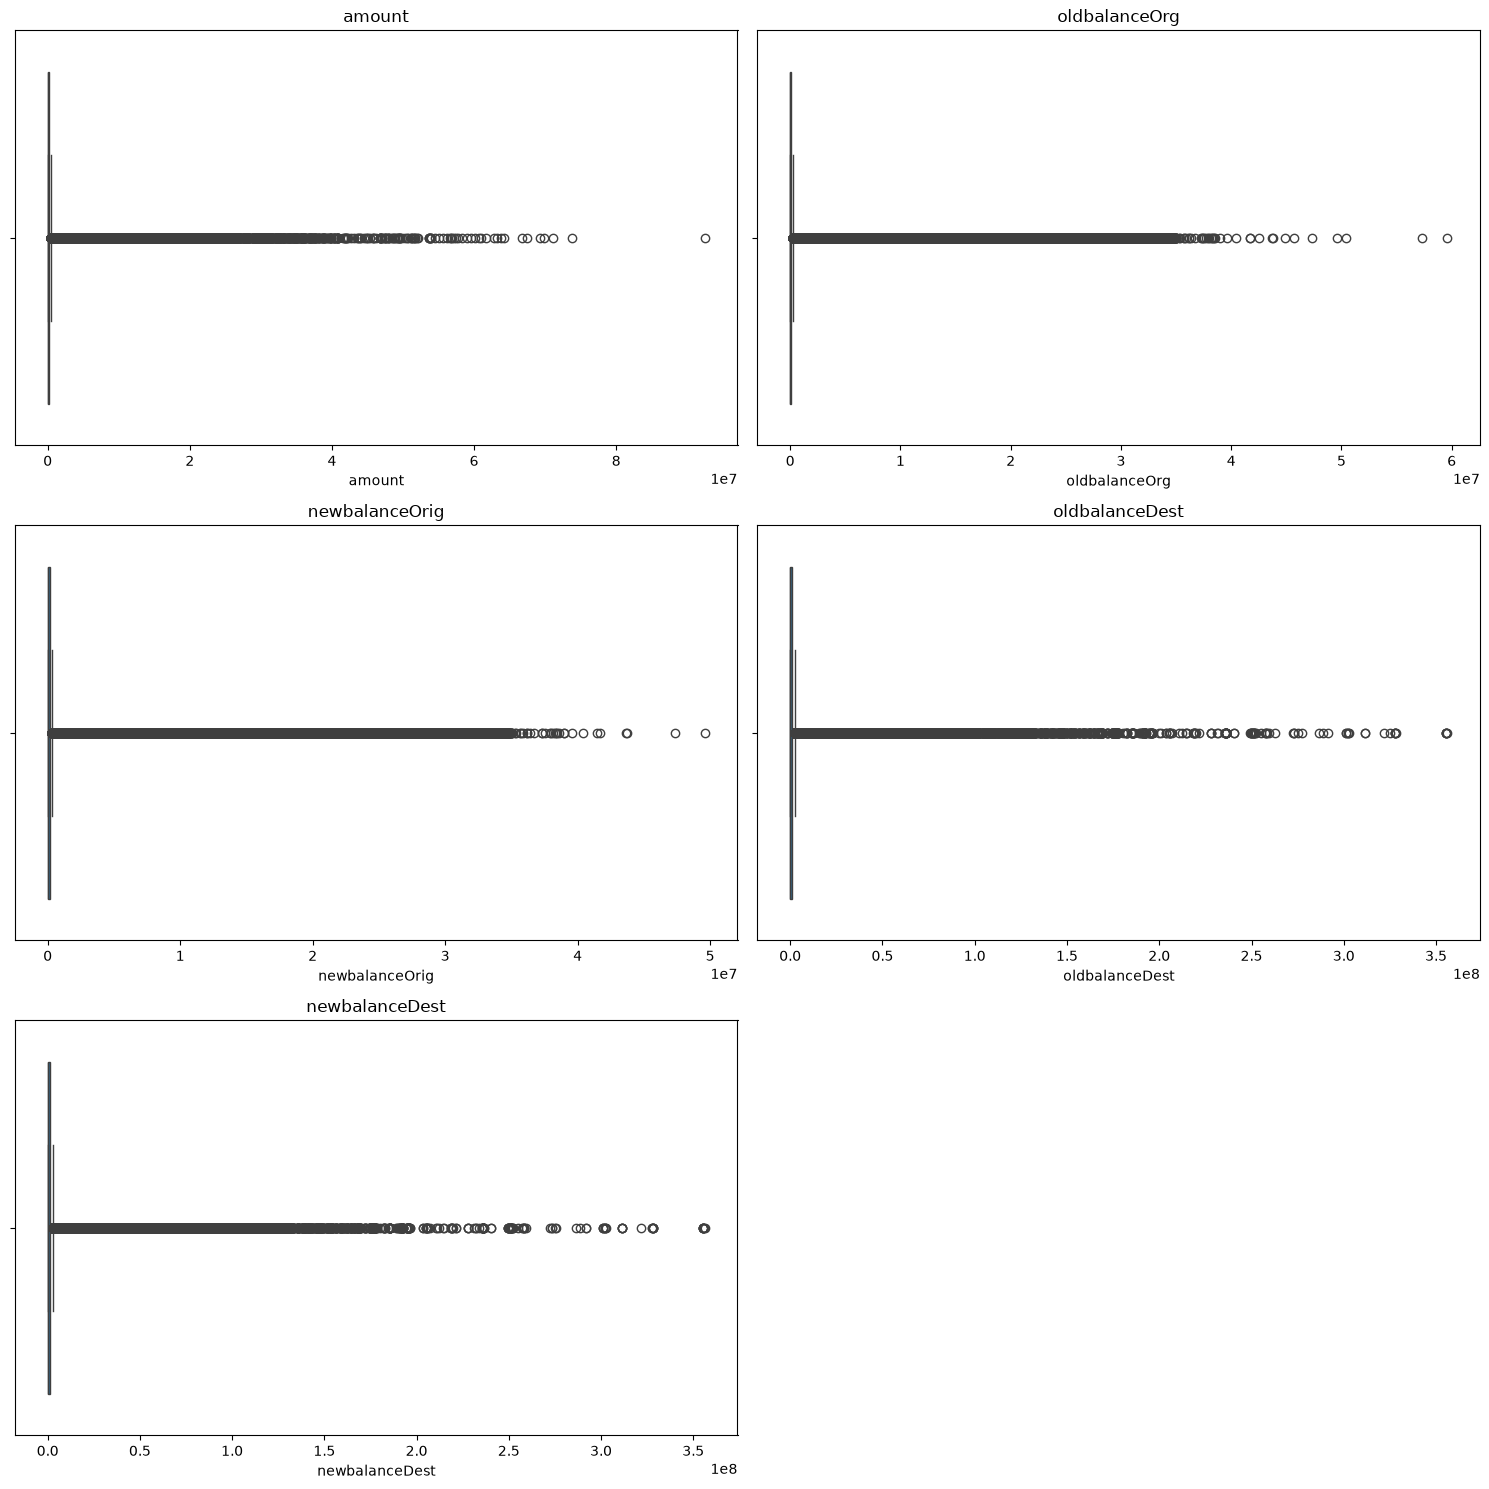

In [16]:
plt.figure(figsize=(15,15))
plotnumber=1#count of no of plots required
for col in numcol:
    if plotnumber<=6:
        ax=plt.subplot(3,2,plotnumber)
        sns.boxplot(data=df,x=df[col])
        plt.title(col)
    plotnumber+=1
plt.tight_layout()

In [17]:
#all num_col has outlier
#Skewness 


for i in numcol:
    print(i)
    print(df[i].skew())

#Normal means skewness b/w -0.5 to 0.5

amount
30.99394948249041
oldbalanceOrg
5.249136420603118
newbalanceOrig
5.176884001159237
oldbalanceDest
19.92175791579108
newbalanceDest
19.352302057660125


In [18]:
#all are skewed
#Treating for skewed data using IQR method

for i in numcol:
    df[i] = df[i].astype(float)
    print(i)
    q1=df[i].quantile(0.25)
    q2=df[i].quantile(0.5)
    q3=df[i].quantile(0.75)
    print(q1,q2,q3)
    iqr=q3-q1
    uplim=q3+1.5*iqr
    lowlim=q1-1.5*iqr
    print(f'iqr={iqr},uplim={uplim},lowlim={lowlim}')
    a=(len(df.loc[df[i]>uplim])/len(df)*100) + (len(df.loc[df[i]<lowlim])/len(df)*100)
    print(a)
    if a<5:
        df.loc[df[i]>uplim,i]=df[i].median()#if data is skewed
        df.loc[df[i]<lowlim,i]=df[i].median()
    else:
        print('Outlier Not Handled') 

amount
13389.57 74871.94 208721.4775
iqr=195331.9075,uplim=501719.33875,lowlim=-279608.29125
5.313502928039078
Outlier Not Handled
oldbalanceOrg
0.0 14208.0 107315.175
iqr=107315.175,uplim=268287.9375,lowlim=-160972.7625
17.485045468690572
Outlier Not Handled
newbalanceOrig
0.0 0.0 144258.41
iqr=144258.41,uplim=360646.025,lowlim=-216387.615
16.5559313616089
Outlier Not Handled
oldbalanceDest
0.0 132705.66499999998 943036.7075
iqr=943036.7075,uplim=2357591.76875,lowlim=-1414555.06125
12.355523353587044
Outlier Not Handled
newbalanceDest
0.0 214661.44 1111909.25
iqr=1111909.25,uplim=2779773.125,lowlim=-1667863.875
11.60727813385052
Outlier Not Handled


In [19]:
#None of the outliers are handled

In [20]:
data = df.copy()

***ENCODING***

In [21]:
for i in catcol:
    print(df[i].value_counts())

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64
isFraud
0    6354407
1       8213
Name: count, dtype: int64
isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64


In [22]:
#heavily imbalanced data

In [23]:
# Label Encoding for type
from sklearn.preprocessing import LabelEncoder

label = LabelEncoder()

df['type'] = label.fit_transform(df['type'])

print(df['type'].value_counts())

type
1    2237500
3    2151495
0    1399284
4     532909
2      41432
Name: count, dtype: int64


In [24]:
df.select_dtypes(include='object').columns

Index([], dtype='str')

In [25]:
df.head()

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,3,9839.64,170136.00,160296.36,0.00,0.00,0,0
1,1,3,1864.28,21249.00,19384.72,0.00,0.00,0,0
2,1,4,181.00,181.00,0.00,0.00,0.00,1,0
3,1,1,181.00,181.00,0.00,21182.00,0.00,1,0
4,1,3,11668.14,41554.00,29885.86,0.00,0.00,0,0


***EDA***

In [26]:
import matplotlib.ticker as ticker

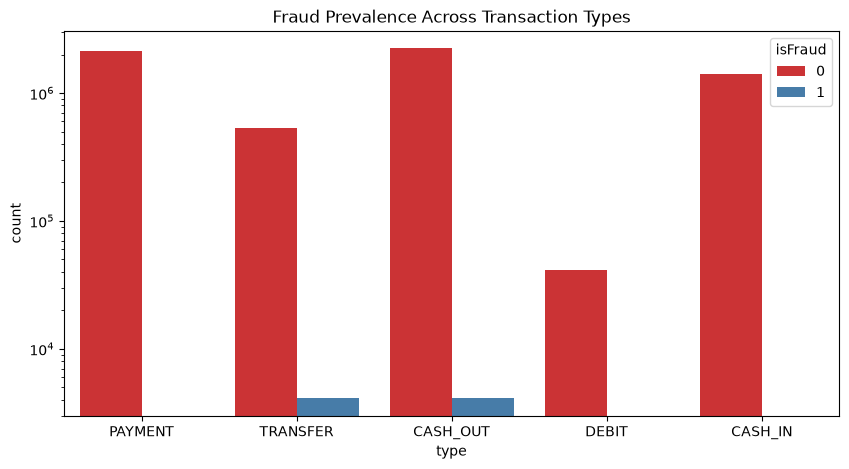

In [27]:
plt.figure(figsize=(10, 5))
sns.countplot(data=data, x='type', hue='isFraud', palette='Set1')
plt.yscale('log') 
plt.title('Fraud Prevalence Across Transaction Types')
plt.show()

In [28]:
'''
Fraudulent transactions (isFraud = 1) occur exclusively in TRANSFER and CASH_OUT categories and are completely absent in PAYMENT, DEBIT, and CASH_IN.
'''

'\nFraudulent transactions (isFraud = 1) occur exclusively in TRANSFER and CASH_OUT categories and are completely absent in PAYMENT, DEBIT, and CASH_IN.\n'

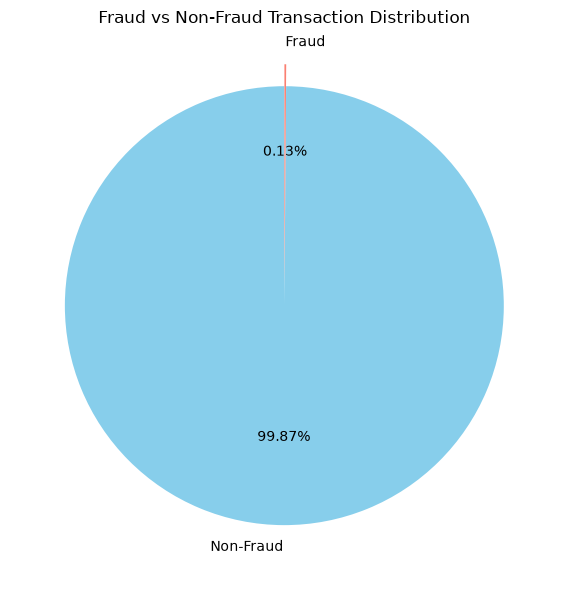

In [29]:
fraud_counts = data['isFraud'].value_counts().sort_index()

plt.figure(figsize=(8,6))

plt.pie(
    fraud_counts,
    labels=['Non-Fraud', 'Fraud'],
    autopct='%1.2f%%',
    startangle=90,
    colors=['skyblue', 'salmon'],
    explode=(0, 0.1)
)

plt.title('Fraud vs Non-Fraud Transaction Distribution')
plt.tight_layout()
plt.show()

In [30]:
#Non-fraudulent transactions account for 99.87% of the dataset, while fraudulent transactions represent a tiny fraction at 0.13%.

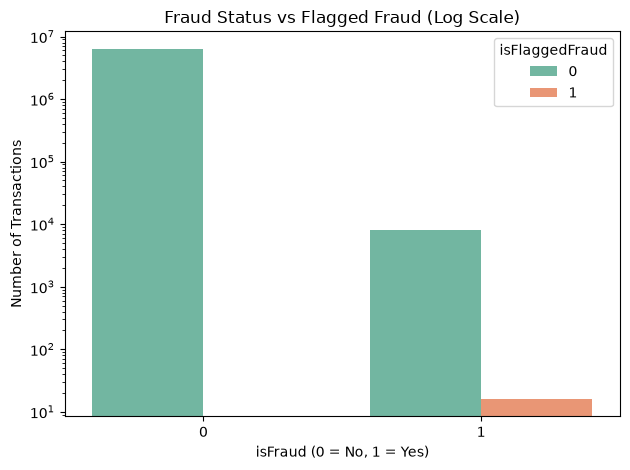

In [31]:
ax = sns.countplot(
    data=data,
    x='isFraud',
    hue='isFlaggedFraud',
    palette='Set2'
)

ax.set_yscale('log')

plt.title('Fraud Status vs Flagged Fraud (Log Scale)')
plt.xlabel('isFraud (0 = No, 1 = Yes)')
plt.ylabel('Number of Transactions')
plt.tight_layout()
plt.show()

In [32]:
'''
The automated rule system (isFlaggedFraud = 1) 
correctly catches only a tiny fraction of total fraud cases.
 The vast majority of actual fraud cases 
 were completely missed by the system and remained unflagged .  
 There are no recorded instances where a legitimate transaction (isFraud = 0) was incorrectly flagged as fraud (isFlaggedFraud = 1).
 '''

'\nThe automated rule system (isFlaggedFraud = 1) \ncorrectly catches only a tiny fraction of total fraud cases.\n The vast majority of actual fraud cases \n were completely missed by the system and remained unflagged .  \n There are no recorded instances where a legitimate transaction (isFraud = 0) was incorrectly flagged as fraud (isFlaggedFraud = 1).\n '

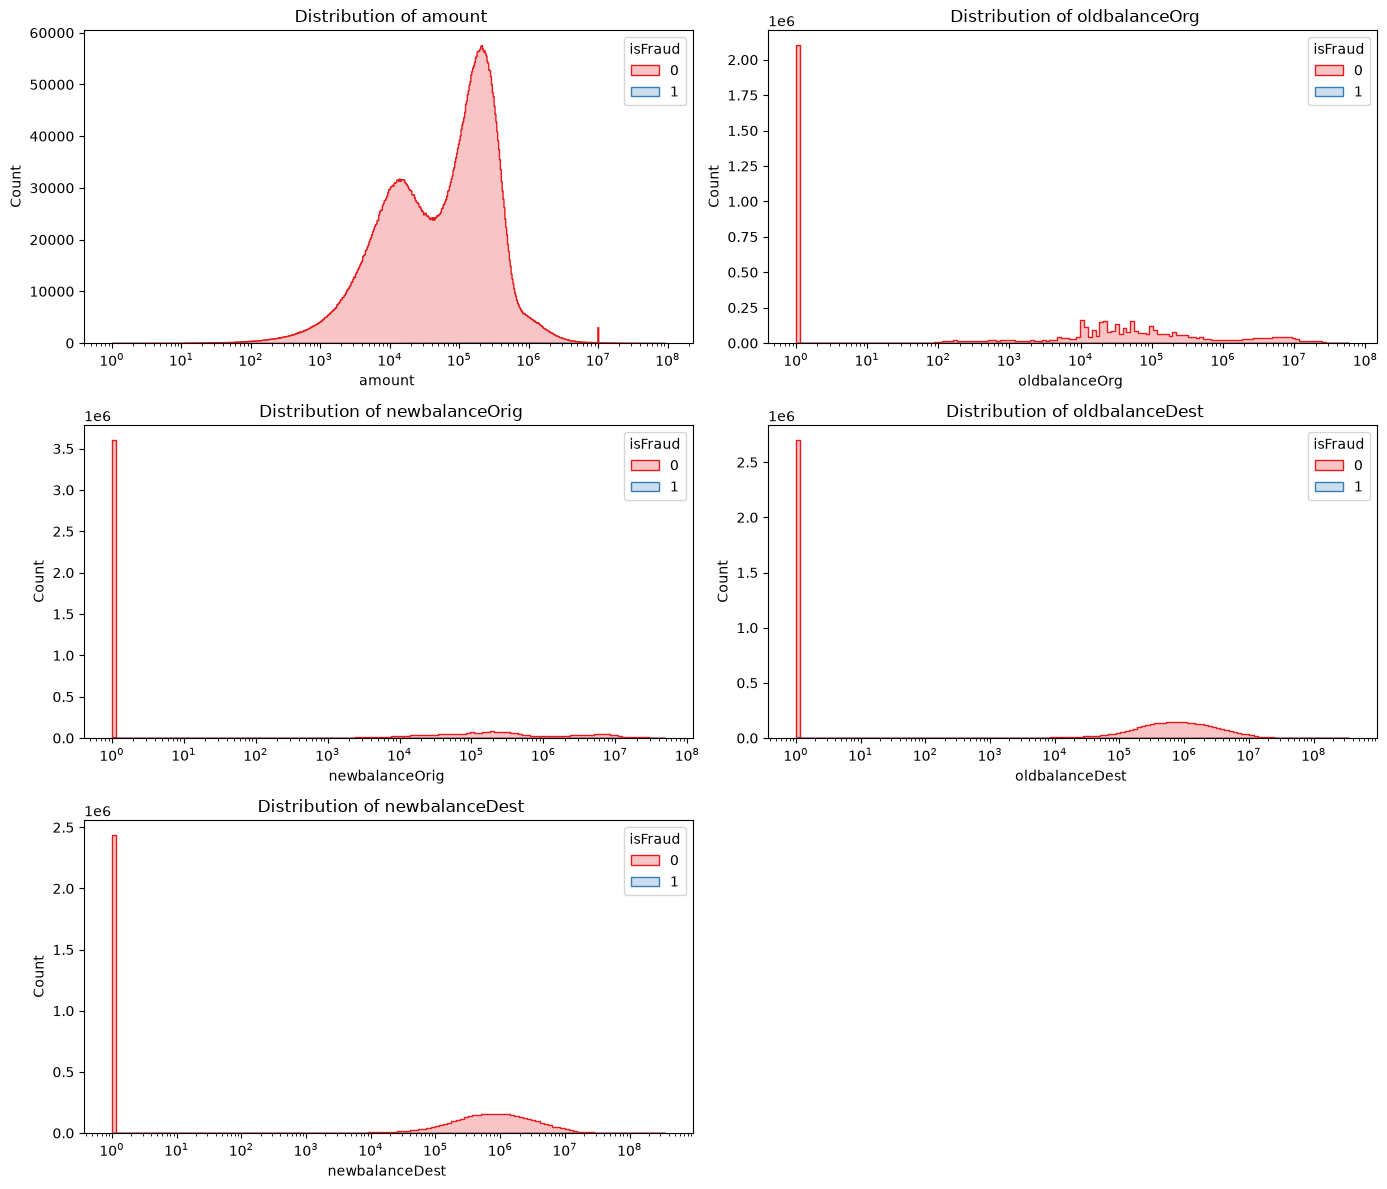

In [33]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten() 

for i, col in enumerate(numcol):
    
    sns.histplot(df, x=df[col] + 1, hue='isFraud', ax=axes[i], log_scale=True, element='step', palette='Set1')
    axes[i].set_title(f' Distribution of {col}')
    axes[i].set_xlabel(f'{col} ')


fig.delaxes(axes[5])
plt.tight_layout()
plt.show()


In [34]:
'''
 Features like amount, oldbalanceOrg, newbalanceOrig,newbalanceDest and oldbalanceDest are heavily right-skewed,
 requiring a logarithmic scale for proper visualization.   
 '''

'\n Features like amount, oldbalanceOrg, newbalanceOrig,newbalanceDest and oldbalanceDest are heavily right-skewed,\n requiring a logarithmic scale for proper visualization.   \n '

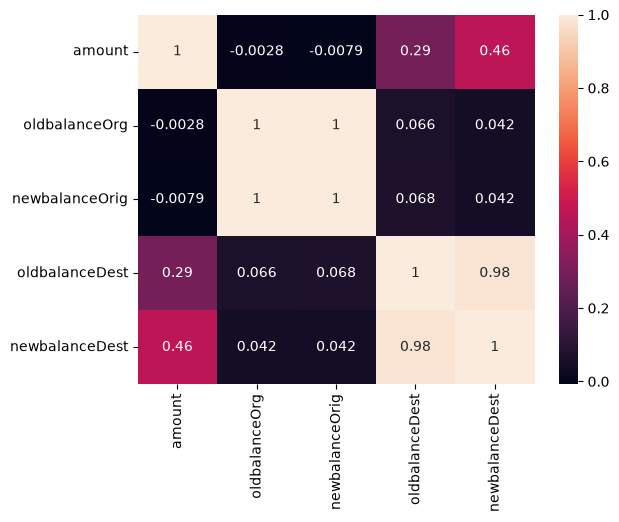

In [35]:
sns.heatmap(data=data[numcol].corr(),annot=True)
plt.show()

In [36]:
'''oldbalanceDest and newbalanceDest exhibit an extremely high correlation of 0.98.
oldbalanceOrg and newbalanceOrig show a perfect correlation of 1.
'''

'oldbalanceDest and newbalanceDest exhibit an extremely high correlation of 0.98.\noldbalanceOrg and newbalanceOrig show a perfect correlation of 1.\n'

In [37]:
# 1. Balance discrepancy error features
df['errorBalanceOrig'] = df['newbalanceOrig'] - df['amount'] - df['oldbalanceOrg']
df['errorBalanceDest'] = df['oldbalanceDest'] + df['amount'] - df['newbalanceDest']

# 2. Account emptying flag
df['is_orig_zero'] = ((df['newbalanceOrig'] == 0) & (df['amount'] > 0)).astype(int)



Error=Old Balance-Amount-New Balance

Error=Old Balance+Amount-New Balance

***DATA SPLITTING***

In [38]:
x=df.drop('isFraud',axis=1)
y=df['isFraud']

In [39]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)

In [40]:
print('Shape of x_train:',x_train.shape)
print('Shape of x_test:',x_test.shape)
print('Shape of y_train:',y_train.shape)
print('Shape of y_test:',y_test.shape)

Shape of x_train: (4453834, 11)
Shape of x_test: (1908786, 11)
Shape of y_train: (4453834,)
Shape of y_test: (1908786,)


In [41]:
from sklearn.preprocessing import StandardScaler
scale=StandardScaler()
x_train_scaled=scale.fit_transform(x_train)
x_test_scaled=scale.transform(x_test)

In [42]:
from collections import Counter
from imblearn.over_sampling import SMOTE
sm=SMOTE()
x_smote,y_smote=sm.fit_resample(x_train_scaled,y_train)#for train data
print('actual data:',Counter(y_train))
print('after smote:',Counter(y_smote))

actual data: Counter({0: 4448056, 1: 5778})
after smote: Counter({0: 4448056, 1: 4448056})


In [43]:
'''
Due to high multicollinearity, we can use tree-based models like LightGBM and XGBoost, 
which handle correlated features well.
'''

'\nDue to high multicollinearity, we can use tree-based models like LightGBM and XGBoost, \nwhich handle correlated features well.\n'

****1) Logistic Regression****

In [44]:
from sklearn.linear_model import LogisticRegression
model_log=LogisticRegression()
model_log.fit(x_smote,y_smote)
y_pred=model_log.predict(x_test_scaled)

In [45]:
from sklearn.metrics import accuracy_score,confusion_matrix,precision_score,recall_score,f1_score,classification_report,roc_curve,auc
print('Metrics Evaluation of Logistic Regression')
print('Accuracy Score =', accuracy_score(y_test, y_pred))
print('Precision Score =', precision_score(y_test, y_pred))
print('Recall Score =', recall_score(y_test, y_pred))
print('F1 Score =', f1_score(y_test, y_pred))
print('Confusion Matrix = \n', confusion_matrix(y_test, y_pred))
print('Classification Report =\n ', classification_report(y_test, y_pred))

fpr,tpr,threshold=roc_curve(y_test,y_pred)
auc_score=auc(fpr,tpr)
print('AUC=',auc_score)
#AUC near to 1 then best model

Metrics Evaluation of Logistic Regression
Accuracy Score = 0.9833286706838797
Precision Score = 0.0684855070335673
Recall Score = 0.9577002053388091
F1 Score = 0.1278298525461821
Confusion Matrix = 
 [[1874632   31719]
 [    103    2332]]
Classification Report =
                precision    recall  f1-score   support

           0       1.00      0.98      0.99   1906351
           1       0.07      0.96      0.13      2435

    accuracy                           0.98   1908786
   macro avg       0.53      0.97      0.56   1908786
weighted avg       1.00      0.98      0.99   1908786

AUC= 0.9705308057508413


****2) XGBoost****

In [46]:
from xgboost import XGBClassifier
model_xgb=XGBClassifier(tree_method='hist')
model_xgb.fit(x_smote,y_smote)
y_pred=model_xgb.predict(x_test_scaled)

In [47]:

print('Metrics Evaluation of XGBoosting')
print('Accuracy Score =', accuracy_score(y_test, y_pred))
print('Precision Score =', precision_score(y_test, y_pred))
print('Recall Score =', recall_score(y_test, y_pred))
print('F1 Score =', f1_score(y_test, y_pred))
print('Confusion Matrix = \n', confusion_matrix(y_test, y_pred))
print('Classification Report =\n ', classification_report(y_test, y_pred))

fpr,tpr,threshold=roc_curve(y_test,y_pred)
auc_score=auc(fpr,tpr)
print('AUC=',auc_score)
#AUC near to 1 then best model

Metrics Evaluation of XGBoosting
Accuracy Score = 0.9982381471783637
Precision Score = 0.41944444444444445
Recall Score = 0.9921971252566735
F1 Score = 0.589627821842587
Confusion Matrix = 
 [[1903007    3344]
 [     19    2416]]
Classification Report =
                precision    recall  f1-score   support

           0       1.00      1.00      1.00   1906351
           1       0.42      0.99      0.59      2435

    accuracy                           1.00   1908786
   macro avg       0.71      1.00      0.79   1908786
weighted avg       1.00      1.00      1.00   1908786

AUC= 0.9952214943444793


****3) LightGBM****

In [48]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


In [49]:
from lightgbm import LGBMClassifier
model_li=LGBMClassifier()
model_li.fit(x_smote,y_smote)
y_pred=model_li.predict(x_test_scaled)

[LightGBM] [Info] Number of positive: 4448056, number of negative: 4448056
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.710454 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2079
[LightGBM] [Info] Number of data points in the train set: 8896112, number of used features: 11
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


In [50]:
print('Metrics Evaluation of LightGBM')
print('Accuracy Score =', accuracy_score(y_test, y_pred))
print('Precision Score =', precision_score(y_test, y_pred))
print('Recall Score =', recall_score(y_test, y_pred))
print('F1 Score =', f1_score(y_test, y_pred))
print('Confusion Matrix = \n', confusion_matrix(y_test, y_pred))
print('Classification Report =\n ', classification_report(y_test, y_pred))

fpr,tpr,threshold=roc_curve(y_test,y_pred)
auc_score=auc(fpr,tpr)
print('AUC=',auc_score)
#AUC near to 1 then best model

Metrics Evaluation of LightGBM
Accuracy Score = 0.9956312546299061
Precision Score = 0.22488350419384903
Recall Score = 0.9909650924024641
F1 Score = 0.36657804785415876
Confusion Matrix = 
 [[1898034    8317]
 [     22    2413]]
Classification Report =
                precision    recall  f1-score   support

           0       1.00      1.00      1.00   1906351
           1       0.22      0.99      0.37      2435

    accuracy                           1.00   1908786
   macro avg       0.61      0.99      0.68   1908786
weighted avg       1.00      1.00      1.00   1908786

AUC= 0.9933011535825589


### Model Performance Comparison

| Metric | Logistic Regression | XGBoost | LightGBM |
|:---|---:|---:|---:|
| Accuracy | 98.33% | **99.82%** | 99.56% |
| Precision | 6.85% | **41.94%** | 22.49% |
| Recall | 95.77% | **99.22%** | 99.10% |
| F1-Score | 12.78% | **58.96%** | 36.66% |
| AUC | 97.05% | **99.52%** | 99.33% |
| True Positives (TP) | 2,332 | 2,416 | 2,413 |
| False Positives (FP) | 31,719 | 3,344 | 8,317 |
| False Negatives (FN) | 103 | 19 | 22 |
| True Negatives (TN) | 1,874,632 | 1,903,007 | 1,898,034 |

### Best Model: XGBoost

XGBoost achieved the best overall performance, with the highest accuracy (99.82%), precision (41.94%), recall (99.22%), F1-score (58.96%), and AUC (99.52%). It detected 2,416 out of 2,435 fraudulent transactions, with only 19 false negatives and 3,344 false positives.



***Feature Importance***

In [52]:
feature_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'Importance': model_xgb.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

             Feature  Importance
8   errorBalanceOrig        0.34
1               type        0.21
10      is_orig_zero        0.16
3      oldbalanceOrg        0.07
4     newbalanceOrig        0.07
9   errorBalanceDest        0.05
6     newbalanceDest        0.05
2             amount        0.03
0               step        0.01
5     oldbalanceDest        0.00
7     isFlaggedFraud        0.00


The feature importance analysis shows that **`errorBalanceOrig` is the most important feature (0.34)**, followed by `type` (0.21) and `is_orig_zero` (0.16). This suggests that discrepancies in the sender's account balance, transaction type, and whether the sender's account becomes empty are the strongest predictors used by the model.

The features `oldbalanceOrg` and `newbalanceOrig` each have an importance of 0.07, while `errorBalanceDest` and `newbalanceDest` each contribute 0.05. The `amount` feature has a relatively low importance of 0.03, and `step` contributes 0.01.

The features `oldbalanceDest` and `isFlaggedFraud` have importance values rounded to 0.00, indicating negligible importance according to this model's importance measure.

Overall, the results highlight the importance of account balance discrepancies and transaction characteristics in predicting fraudulent transactions. 